# Extrasensory perception

Do people who are more extraverted also have more extrasensory perception
(ESP)? Lee & Wagenmakers (2013, chapter 13) answer this question with the
data of Bem (2011) and a correlation model. This case study takes the
PyMC version of the model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts, a skeptic and a believer, give their
   knowledge. `elicito` learns a prior from each expert. PyMC then fits the
   model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.021.
- The translated model draws 10 000 samples 10 to 30 times faster than
  PyMC.
- The correlation alone does not separate $r$ from the spread of the ESP
  ability. Two targets of the group, the standard deviations of the
  correct shares and of the extraversion scores, add this spread.
- The elicited quantiles agree with the quantiles of both experts. For
  the skeptic, the elicited quantiles of the correlation are wider.
- The posterior mean of $r$ is 0.12 for the skeptic and 0.22 for the
  believer, with 0.16 for the book prior. The believer expects 0.56: the
  100 participants move the posterior far from this prior.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import pytensor.tensor as pt
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 13], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The experiment

In the experiment of Bem (2011), 100 participants try to predict where a
picture will appear on a screen. Each participant makes 60 predictions.
Without ESP, a participant is correct in half of the trials. Each
participant also gets an extraversion score between 0 and 100.

The figure shows the number of correct predictions against the
extraversion score. One dot is one participant.

In [4]:
data = np.loadtxt("data/bem-extraversion.csv", delimiter=",", skiprows=1)
k = data[:, 0].astype(int)  # correct predictions in the first session
x = data[:, 2]  # extraversion score
N_TRIALS = 60
N_PARTICIPANTS = len(k)
SIGMA_X = 3.0  # measurement error of the extraversion score

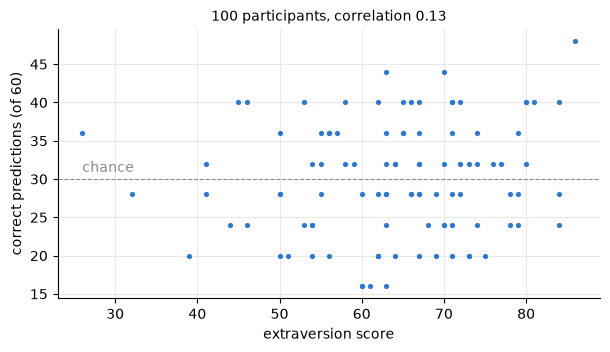

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(x, k, s=14, color=BLUE, lw=0)
ax.axhline(N_TRIALS / 2, color=GREY, lw=0.8, ls="--")
ax.text(x.min(), N_TRIALS / 2 + 0.5, "chance", color=GREY, va="bottom")
ax.set(
    xlabel="extraversion score",
    ylabel=f"correct predictions (of {N_TRIALS})",
    title=f"{N_PARTICIPANTS} participants, correlation "
    f"{np.corrcoef(k, x)[0, 1]:.2f}",
)
plt.show()

Most participants are near chance: the mean share of correct predictions
is 0.50, and 48 of the 100 participants have more than 30 correct. The
correlation with extraversion is weak, 0.13.

## The model

Each participant $p$ has a latent ESP ability $\theta_{1p}$ and a latent
extraversion $\theta_{2p}$. The two have a bivariate Normal distribution
with the means $\mu_1, \mu_2$, the standard deviations
$\sigma_1 = 1/\sqrt{\lambda_1}, \sigma_2 = 1/\sqrt{\lambda_2}$ and the
**correlation** $r$. The correlation is the quantity of interest.

The observations are

$$k_p \sim \operatorname{Binomial}(60, \Phi(\theta_{1p})), \qquad
x_p \sim \operatorname{Normal}(100\,\Phi(\theta_{2p}), 3),$$

with $\Phi$ the cumulative distribution function of the standard Normal.
The book gives $\mu_1$ and $\mu_2$ a Normal prior, $\lambda_1$ and
$\lambda_2$ a Gamma prior, and $r$ a Uniform prior on $(0, 1)$.

The port changes three things. None of them changes the model for the
data.

- **The bivariate Normal has no matrix.** The book inverts the covariance
  matrix. During the elicitation, the search tries hyperparameters that
  make this matrix singular. The port therefore writes the bivariate
  Normal with two standard Normal variables $z_1, z_2$:

  $$\theta_{1p} = \mu_1 + \sigma_1 z_{1p}, \qquad
  \theta_{2p} = \mu_2 + \sigma_2 \bigl(r z_{1p} + \sqrt{1 - r^2}\, z_{2p}\bigr).$$

- **The correlation can be negative.** A skeptic expects $r$ near 0. On
  $(0, 1)$, this value is at the edge, and the learned prior then has an
  infinite density at 0. PyMC cannot sample such a posterior well. The port
  therefore uses $r = 2\rho - 1$ with $\rho \sim \operatorname{Beta}$, so
  $r$ is in $(-1, 1)$. The reference prior $\operatorname{Beta}(1, 1)$
  gives $r \sim \operatorname{Uniform}(-1, 1)$.
- **Each mean has its own prior.** Ability and extraversion have different
  scales.

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node.

In [6]:
def normal_prior(name: str) -> Any:
    """Add a Normal(0, 1 / sqrt(0.001)) prior with pm.Data inputs"""
    mu = pm.Data(f"{name}_mu", 0.0)
    sigma = pm.Data(f"{name}_sigma", 1 / np.sqrt(0.001))
    return pm.Normal(name, mu=mu, sigma=sigma)


def gamma_prior(name: str) -> Any:
    """Add a Gamma(0.001, 0.001) prior with pm.Data inputs"""
    alpha = pm.Data(f"{name}_alpha", 0.001)
    beta = pm.Data(f"{name}_beta", 0.001)
    return pm.Gamma(name, alpha=alpha, beta=beta)


def phi(value: Any) -> Any:
    """Cumulative distribution function of the standard Normal"""
    return 0.5 + 0.5 * pm.math.erf(value / np.sqrt(2))


with pm.Model() as model:
    rho = pm.Beta("rho", alpha=pm.Data("rho_alpha", 1.0), beta=pm.Data("rho_beta", 1.0))
    r = pm.Deterministic("r", 2 * rho - 1)
    mu1, mu2 = normal_prior("mu1"), normal_prior("mu2")
    lambda1, lambda2 = gamma_prior("lambda1"), gamma_prior("lambda2")
    sigma1, sigma2 = 1 / pm.math.sqrt(lambda1), 1 / pm.math.sqrt(lambda2)

    z = pm.Normal("z", 0.0, 1.0, shape=(N_PARTICIPANTS, 2))
    theta1 = mu1 + sigma1 * z[:, 0]
    theta2 = mu2 + sigma2 * (r * z[:, 0] + pt.sqrt(1 - r**2) * z[:, 1])

    pm.Binomial("ki", p=phi(theta1), n=N_TRIALS, observed=k)
    pm.Normal("xi", mu=100 * phi(theta2), sigma=SIGMA_X, observed=x)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads. The
standard Normal variables $z$ have no `pm.Data` input, so they are not
priors: the translated model samples them. `adapter_pymc.model` returns
the translated model. It returns each observed variable and each
`pm.Deterministic` by name: here `ki`, `xi` and `r`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('rho', 'Beta'), ('mu1', 'Normal'), ('mu2', 'Normal'), ('lambda1', 'Gamma'), ('lambda2', 'Gamma')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. Each output has one value for each
participant. The table shows the largest $D$ of these 100 values.

Most draws of the book prior $\operatorname{Gamma}(0.001, 0.001)$ are 0
in float64. $\sigma$ is then infinite, and both models give NaN. The book
prior of the means, with standard deviation 31.6, also puts almost every
participant at 0 or 60 correct predictions. The check therefore uses
$\operatorname{Gamma}(2, 2)$ for $\lambda_1$ and $\lambda_2$, and
$\operatorname{Normal}(0, 1)$ for $\mu_1$ and $\mu_2$. The translation
does not depend on these values.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


LAMBDAS = [
    f"{name}_{arg}" for name in ("lambda1", "lambda2") for arg in ("alpha", "beta")
]
MEANS = ("mu1", "mu2")
BOOK_PRIOR = {name: 0.001 for name in LAMBDAS}
BOOK_PRIOR |= {f"{mean}_mu": 0.0 for mean in MEANS}
BOOK_PRIOR |= {f"{mean}_sigma": 1 / np.sqrt(0.001) for mean in MEANS}
CHECK_PRIOR = BOOK_PRIOR | {name: 2.0 for name in LAMBDAS}
CHECK_PRIOR |= {f"{mean}_sigma": 1.0 for mean in MEANS}
pm.set_data(CHECK_PRIOR, model=model)

OUTPUTS = ("r", "ki", "xi")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<8}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<8}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output     TensorFlow mean, sd     PyMC mean, sd       D
r                   0.00, 0.58       -0.01, 0.58   0.013
ki                30.02, 21.41      29.89, 21.44   0.021
xi                49.60, 35.64      49.73, 35.56   0.020


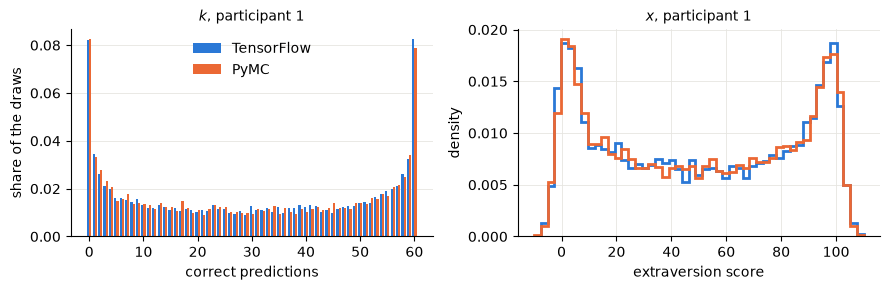

In [9]:
fig, (ax_k, ax_x) = plt.subplots(1, 2, figsize=(9, 3))
counts = np.arange(N_TRIALS + 1)
for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["ki"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, 0].astype(int), minlength=N_TRIALS + 1) / DRAWS
    ax_k.bar(counts + offset, share, width=0.4, color=color, label=label)
ax_k.set(
    xlabel="correct predictions",
    ylabel="share of the draws",
    title="$k$, participant 1",
)
ax_k.grid(axis="x", visible=False)
ax_k.legend()

bins = np.linspace(-10, 110, 50)
for (label, values), color in zip(samples["xi"].items(), (BLUE, ORANGE)):
    ax_x.hist(values[:, 0], bins, density=True, histtype="step", lw=2, color=color)
ax_x.set(xlabel="extraversion score", ylabel="density", title="$x$, participant 1")
fig.tight_layout()
plt.show()

The distributions of the two models overlap.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

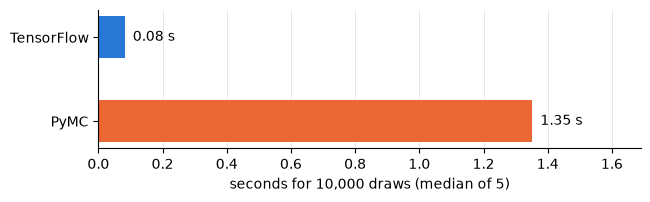

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.barh(list(seconds), list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is 10 to 30 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

Both experts know the same about ability and extraversion. They differ in
the correlation $r$:

| Expert | $\rho$ | mean and sd of $r$ | Description |
| :-- | :-- | :-- | :-- |
| Skeptic | Beta(150, 150) | 0, 0.06 | no link between ESP and extraversion |
| Believer | Beta(25, 7) | 0.56, 0.14 | extraverts have more ESP |

The model has $\rho = (r + 1) / 2$, so the simulated experts give the
prior of $\rho$. Their priors have the Beta family of the model, so a
perfect elicitation can learn them exactly.

Each expert gives quantiles of five quantities:

- the share of correct predictions of one participant, $k / 60$,
- the extraversion score of one participant, divided by 100,
- the correlation of the correct predictions and the extraversion score,
  over 100 participants,
- the standard deviation of the correct shares of the 100 participants,
- the standard deviation of the extraversion scores of the 100
  participants, divided by 100.

Questions that an expert can answer:

- **correct share:** "Of 60 predictions, how many does a typical
  participant get right?"
- **extraversion:** "What extraversion score, from 0 to 100, does a
  typical participant have?"
- **correlation:** "In a group of 100 participants, how strongly do
  extraverts predict better than introverts?" An expert can answer with
  a correlation, or with an example: "the 10 most extraverted
  participants make 3 more correct predictions than the 10 least
  extraverted."
- **sd of correct shares:** "How much do participants differ in their
  number of correct predictions?"
- **sd of extraversion:** "How much do participants differ in their
  extraversion score?"

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

The two standard deviations describe the spread of the group. They fix
$\sigma_1$ and $\sigma_2$. Without them, the correlation cannot separate
$r$ from $\sigma_1$: the section [Why the spread
matters](#why-the-spread-matters) shows it.

The five quantities are all between -1 and 1. A quantity with larger
values, for example the raw score, would dominate the loss, and
`elicito` would then not learn the correlation.

In [12]:
COMMON = {
    "mu1": tfd.Normal(0.0, 0.05),
    "mu2": tfd.Normal(0.35, 0.1),
    "lambda1": tfd.Gamma(10.0, 0.7),
    "lambda2": tfd.Gamma(10.0, 1.0),
}
EXPERTS = {
    "Skeptic": {"rho": tfd.Beta(150.0, 150.0), **COMMON},
    "Believer": {"rho": tfd.Beta(25.0, 7.0), **COMMON},
}


def correct_share(ki: Any) -> Any:
    """Share of correct predictions"""
    return ki / N_TRIALS


def extraversion(xi: Any) -> Any:
    """Extraversion score, divided by 100"""
    return xi / 100


def correlation(ki: Any, xi: Any) -> Any:
    """Correlation of ki and xi over the participants"""
    k_centered = ki - tf.reduce_mean(ki, axis=-1, keepdims=True)
    x_centered = xi - tf.reduce_mean(xi, axis=-1, keepdims=True)
    cross = tf.reduce_sum(k_centered * x_centered, axis=-1)
    norm = tf.reduce_sum(k_centered**2, axis=-1) * tf.reduce_sum(x_centered**2, axis=-1)
    return cross / tf.sqrt(norm)


def sd_correct_share(ki: Any) -> Any:
    """Return the standard deviation of the correct shares of the group"""
    return tf.math.reduce_std(correct_share(ki), axis=-1)


def sd_extraversion(xi: Any) -> Any:
    """Return the standard deviation of the extraversion scores of the group"""
    return tf.math.reduce_std(extraversion(xi), axis=-1)


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("correct share", output=correct_share, probs=PROBS),
    el.quantiles("extraversion", output=extraversion, probs=PROBS),
    el.quantiles("correlation", output=correlation, probs=PROBS),
    el.quantiles("sd of correct shares", output=sd_correct_share, probs=PROBS),
    el.quantiles("sd of extraversion", output=sd_extraversion, probs=PROBS),
]

In [13]:
fits = {}
for name, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=800, verbose=False)
    fits[name] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

With 800 evaluations, CMA-ES runs about 80 generations, and the loss
levels off after about 50. The elicited quantiles of the correct share
and of the extraversion are on the diagonal. For the skeptic, the
elicited quantiles of the correlation are wider than those of the
expert: -0.3 instead of -0.15 at the 10 % quantile. The quantiles of the
two standard deviations differ between the replications.

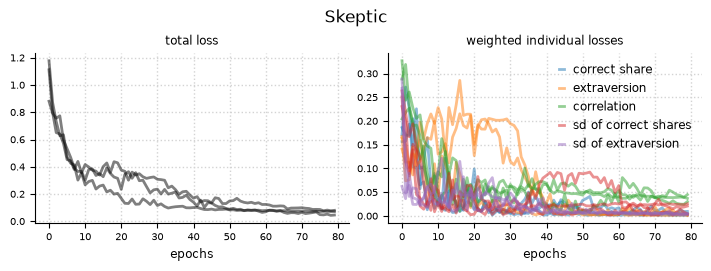

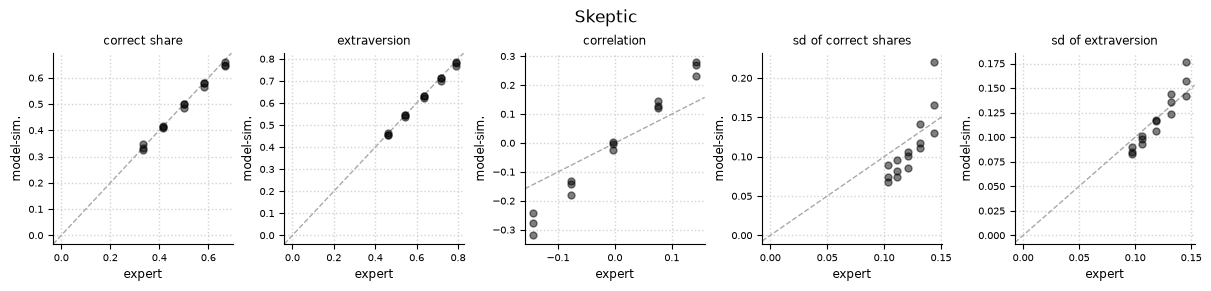

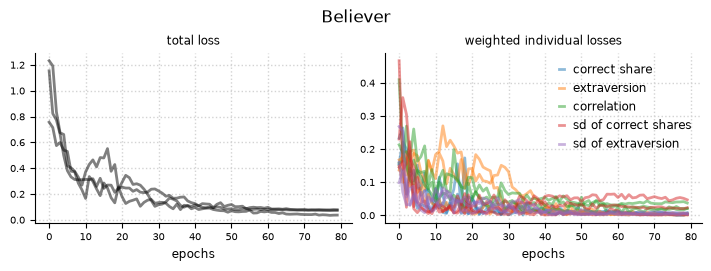

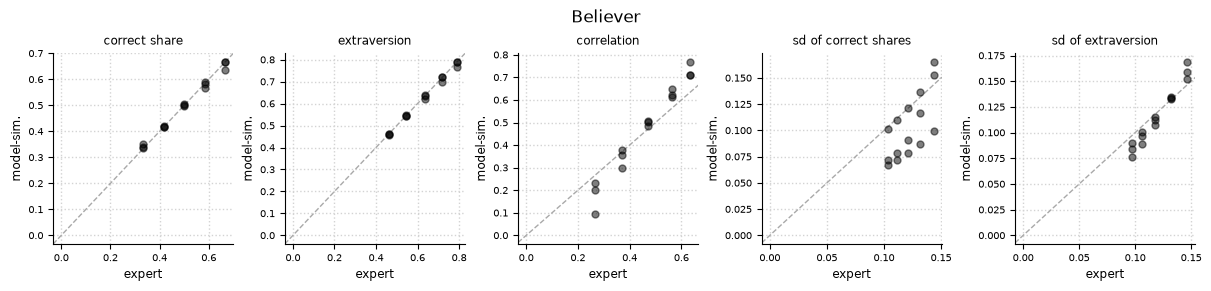

In [14]:
for name, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(name)
    plt.show()
    fig, _ = fit.plot.elicits(cols=5, figsize=(12, 2.8))
    fig.suptitle(name)
    plt.show()

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The book prior, with
$r \sim \operatorname{Uniform}(-1, 1)$, is the reference. We use the
replication with the lowest loss.

In [15]:
PRIORS = {"Book": {"rho_alpha": 1.0, "rho_beta": 1.0, **BOOK_PRIOR}}
PRIORS |= {name: fit.hyperparameters() for name, fit in fits.items()}

posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(3000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata
    predictives[label] = idata.posterior_predictive

print(f"{'prior':<10}{'r mean':>8}{'90 % interval':>16}{'divergences':>13}")
for label, idata in posteriors.items():
    values = idata.posterior["r"].values.ravel()
    low, high = np.quantile(values, [0.05, 0.95])
    divergences = int(idata.sample_stats["diverging"].sum())
    print(
        f"{label:<10}{values.mean():>8.2f}{f'{low:.2f}, {high:.2f}':>16}"
        f"{divergences:>13}"
    )

Output()

Output()

Output()

prior       r mean   90 % interval  divergences
Book          0.16     -0.04, 0.35            0
Skeptic       0.12     -0.04, 0.29            0
Believer      0.22      0.04, 0.39            0


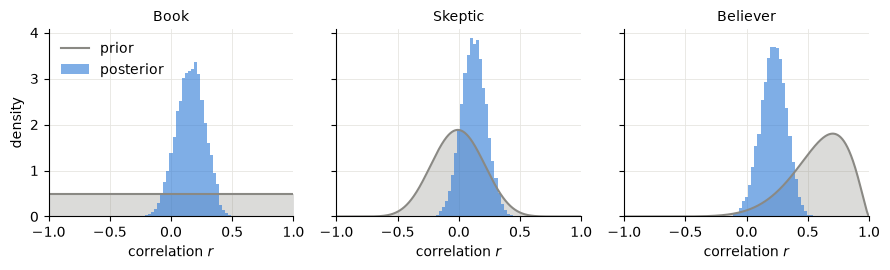

In [16]:
grid = np.linspace(-1, 1, 1000)

fig, axs = plt.subplots(1, len(PRIORS), figsize=(9, 2.8), sharey=True)
for ax, (label, prior) in zip(axs, PRIORS.items()):
    # the density of r = 2 rho - 1
    prior_density = 0.5 * stats.beta(prior["rho_alpha"], prior["rho_beta"]).pdf(
        (grid + 1) / 2
    )
    ax.fill_between(grid, prior_density, color=GREY, alpha=0.3, lw=0)
    ax.plot(grid, prior_density, color=GREY, lw=1.5, label="prior")
    ax.hist(
        posteriors[label].posterior["r"].values.ravel(),
        bins=np.linspace(-1, 1, 80),
        density=True,
        histtype="stepfilled",
        color=BLUE,
        alpha=0.6,
        label="posterior",
    )
    ax.set(title=label, xlabel="correlation $r$", xlim=(-1, 1))
axs[0].set_ylabel("density")
axs[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

The learned priors now show what the experts believe. The prior of the
skeptic is centered at 0, and the prior of the believer has its mode
near 0.7. Both are wider than the priors of the experts. The posterior
mean of $r$ is 0.12 for the skeptic and 0.22 for the believer. The book
prior gives 0.16. The data move the posterior of the believer from the
expected 0.56 to 0.22.

## Why the spread matters

The experts give the standard deviations of the group in addition to
the correlation. This section shows why the correlation alone is not
enough.

The binomial noise of 60 trials weakens the observed correlation of $k$
and $x$. A small $\sigma_1$ weakens it more. The figure runs the
translated model with fixed $\mu_1 = 0$, $\mu_2 = 0.35$ and
$\sigma_2 = 0.3$. It shows the mean observed correlation over 2000 draws,
for each value of $r$ and $\sigma_1$. The band is $\pm$ one standard
deviation over the draws.

In [17]:
SENSITIVITY_DRAWS = 2000
R_GRID = np.linspace(-0.9, 0.9, 13)
SIGMA1_VALUES = (0.05, 0.15, 0.3)
names = [p["name"] for p in adapter_pymc.parameters(model)]


def observed_correlation(r_value: float, sigma1: float) -> Any:
    """Draw the correlation of ki and xi for fixed parameters"""
    values = {
        "rho": (r_value + 1) / 2,
        "mu1": 0.0,
        "mu2": 0.35,
        "lambda1": 1 / sigma1**2,
        "lambda2": 1 / 0.3**2,
    }
    fixed = np.tile([values[name] for name in names], (1, SENSITIVITY_DRAWS, 1))
    out = generative_model(tf.constant(fixed, tf.float32), seed=seed_model)
    return correlation(out["ki"], out["xi"]).numpy()[0]


sensitivity = {
    sigma1: np.array([observed_correlation(value, sigma1) for value in R_GRID])
    for sigma1 in SIGMA1_VALUES
}

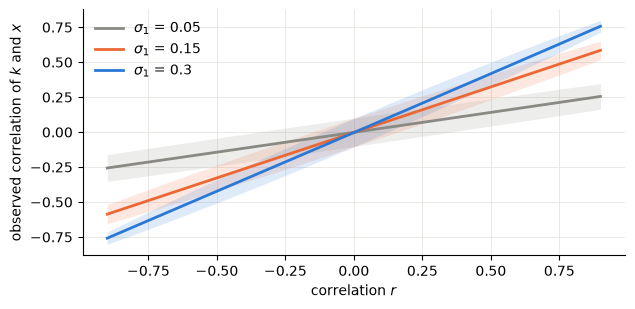

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for sigma1, color in zip(SIGMA1_VALUES, (GREY, ORANGE, BLUE)):
    mean, sd = sensitivity[sigma1].mean(axis=1), sensitivity[sigma1].std(axis=1)
    ax.fill_between(R_GRID, mean - sd, mean + sd, color=color, alpha=0.15, lw=0)
    ax.plot(R_GRID, mean, color=color, lw=2, label=f"$\\sigma_1$ = {sigma1}")
ax.set(xlabel="correlation $r$", ylabel="observed correlation of $k$ and $x$")
ax.legend(loc="upper left")
plt.show()

The lines have different slopes. The same observed correlation, about
0.25, comes from $r = 0.9$ with $\sigma_1 = 0.05$, or from $r = 0.3$ with
$\sigma_1 = 0.3$. The targets fix the observed correlation, but not
$\sigma_1$. `elicito` can therefore match the quantiles of each expert
with many pairs of $r$ and $\sigma_1$.

A target that fixes $\sigma_1$ separates the two: the standard deviation
of the correct shares over the participants. It depends on $\sigma_1$,
and not on $r$. With this target, the correlation then fixes $r$.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The first figure shows the correct predictions against the
extraversion score. The check uses three summaries of it: the mean share
of correct predictions, the mean extraversion score, and the
correlation. A histogram shows the simulated values, the line the
observed value.

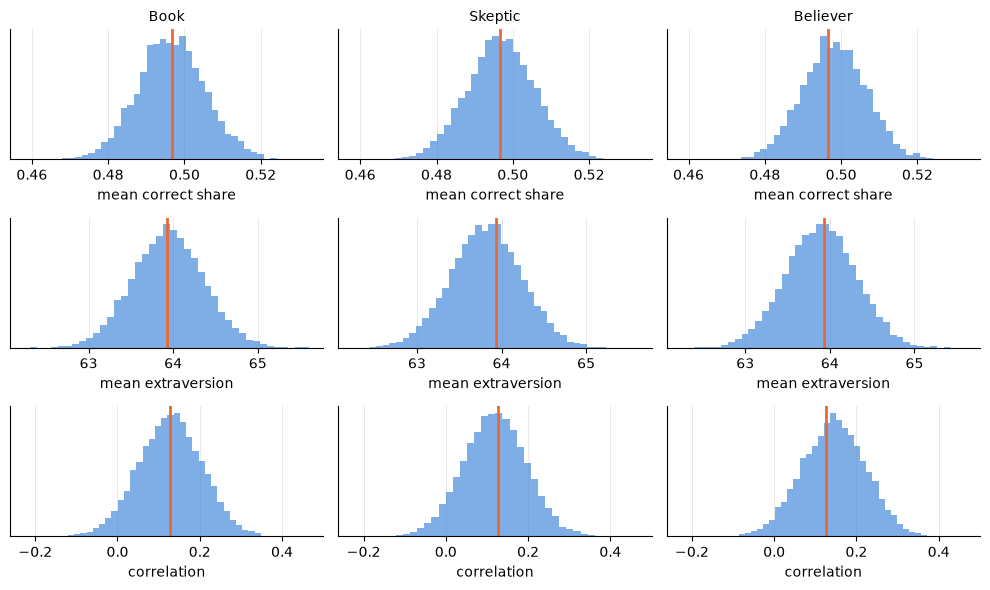

In [19]:
def correlation_rows(a: Any, b: Any) -> Any:
    """Return the correlation of a and b in each row"""
    a_c = a - a.mean(axis=1, keepdims=True)
    b_c = b - b.mean(axis=1, keepdims=True)
    return (a_c * b_c).sum(axis=1) / np.sqrt(
        (a_c**2).sum(axis=1) * (b_c**2).sum(axis=1)
    )


SUMMARIES = {
    "mean correct share": (
        lambda k_rep, x_rep: k_rep.mean(axis=1) / N_TRIALS,
        k.mean() / N_TRIALS,
    ),
    "mean extraversion": (lambda k_rep, x_rep: x_rep.mean(axis=1), x.mean()),
    "correlation": (correlation_rows, np.corrcoef(k, x)[0, 1]),
}

fig, axs = plt.subplots(len(SUMMARIES), len(PRIORS), figsize=(10, 6), sharex="row")
for col, (label, predictive) in enumerate(predictives.items()):
    k_rep = predictive["ki"].values.reshape(-1, N_PARTICIPANTS)
    x_rep = predictive["xi"].values.reshape(-1, N_PARTICIPANTS)
    for row, (name, (summary, observed)) in enumerate(SUMMARIES.items()):
        ax = axs[row, col]
        ax.hist(summary(k_rep, x_rep), bins=40, color=BLUE, alpha=0.6)
        ax.axvline(observed, color=ORANGE, lw=2)
        ax.set(xlabel=name, yticks=[])
        if row == 0:
            ax.set_title(label)
fig.tight_layout()
plt.show()

For all three priors, the observed values are near the center of the
simulated values. The model fits these three summaries of the data, and
the check cannot tell the priors apart.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the three outputs is 0.021.
- **Speed.** The translated model is 10 to 30 times faster than PyMC.
- **Model form.** Write the model so that the search cannot break it: a
  bivariate Normal without a matrix inverse, and a correlation whose
  expected value is not at the edge of its range.
- **Scale of the targets.** Give the targets similar scales. Otherwise
  the target with the largest values dominates the loss.
- **Targets and parameters.** Matching quantiles do not guarantee an
  informative prior. If two parameters have the same effect on the
  targets, add a target that separates them. Here, the standard
  deviations of the group separate $r$ from $\sigma_1$.

## Appendix

The PyMC3 model comes from the notebook
[ExtrasensoryPerception.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/ExtrasensoryPerception.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [20]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Bem, D. J. (2011). Feeling the future: Experimental evidence for anomalous
  retroactive influences on cognition and affect. *Journal of Personality
  and Social Psychology*, 100, 407-425.
- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.